# Módulo 57: Contar historias con datos

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio [m57-storytelling.ipynb](m57-storytelling.ipynb). No es una tarea entregada del programa.

Un análisis correcto que nadie entiende no cambia ninguna decisión. **Contar historias con datos** (*data storytelling*) es el oficio de convertir un hallazgo en un mensaje que una audiencia concreta comprenda, recuerde y pueda usar. En esta lección combinamos tres tradiciones del diseño de gráficos (Tufte, la psicología de la Gestalt y el trabajo de Nigel Holmes) con las herramientas de matplotlib, usando datos de la ONU sobre la estructura de las economías: qué parte del valor agregado bruto aporta la agricultura, la industria y los servicios (`valor-agregado-bruto-por-actividad.csv`).

1. Qué es contar historias con datos
2. Preparar los datos
3. Elegir el gráfico según la pregunta
4. Tufte: proporción datos-tinta y *chartjunk*
5. Leyes de la Gestalt
6. Holmes: el adorno memorable
7. Resaltar con color y anotaciones
8. Rediseño: antes y después
9. Errores frecuentes
10. Ejercicio

## 1. Qué es contar historias con datos

Una historia con datos tiene tres ingredientes:

| Ingrediente | Pregunta que responde | Ejemplo |
| --- | --- | --- |
| **Mensaje** | ¿Qué debe saber o hacer la audiencia al terminar? | "La economía china pasó de la fábrica a los servicios" |
| **Audiencia** | ¿Quién lo verá, qué sabe ya y qué necesita decidir? | Un comité directivo con cinco minutos, no un equipo técnico |
| **Arco narrativo** | ¿En qué orden se presenta la información? | Contexto → tensión o cambio → resolución y siguiente paso |

Una prueba útil antes de dibujar nada: escribir el mensaje en **una frase con verbo** y de no más de dos líneas. Si no se puede, el problema todavía es de análisis, no de diseño.

## 2. Preparar los datos

Antes de contar una historia hay que entender la estructura del archivo. Las primeras líneas muestran una fila de título, los encabezados reales en la segunda línea y una columna sin nombre que contiene el país.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

archivo = "valor-agregado-bruto-por-actividad.csv"
with open(archivo, encoding="cp1252") as f:
    for _ in range(3):
        print(f.readline().strip()[:120])

T14,Gross value added by kind of economic activity,,,,,
Region/Country/Area,,Year,Series,Value,Footnotes,Source
4,Afghanistan,1995,"Agriculture, hunting, forestry and fishing (% of gross value added)",66.3,Data classified according 


Leemos con `header=1` y la codificación `cp1252` (Windows-1252), que interpreta bien nombres como "Côte d’Ivoire". El archivo está en formato largo: una fila por país, año y sector. Cada valor es el **porcentaje del valor agregado bruto** que aporta el sector, así que los tres sectores de un país y año suman alrededor de 100.

In [2]:
datos = pd.read_csv(archivo, encoding="cp1252", header=1)
datos = datos.rename(columns={"Unnamed: 1": "pais", "Year": "anio", "Value": "valor"})
datos["sector"] = datos["Series"].map({
    "Agriculture, hunting, forestry and fishing (% of gross value added)": "Agricultura",
    "Industry (% of gross value added)": "Industria",
    "Services (% of gross value added)": "Servicios",
})

print(datos[["pais", "anio", "sector", "valor"]].head(3))
print("\nPaíses:", datos["pais"].nunique(), "| años:", sorted(datos["anio"].unique().tolist()))
print(datos["sector"].value_counts())

          pais  anio       sector  valor
0  Afghanistan  1995  Agricultura   66.3
1  Afghanistan  2005  Agricultura   37.3
2  Afghanistan  2010  Agricultura   33.2

Países: 214 | años: [1995, 2005, 2010, 2015, 2019, 2020, 2021]
sector
Industria      1483
Servicios      1483
Agricultura    1464
Name: count, dtype: int64


Los años **no están equiespaciados**: hay un salto de diez años entre 1995 y 2005 y después años consecutivos. Lo tendremos en cuenta al graficar. Pasamos a formato ancho los datos de China, el país de nuestra historia:

In [3]:
china = datos[datos["pais"] == "China"].pivot(index="anio", columns="sector", values="valor")
china.columns.name = None
print(china)
print("\nSuma por año:", china.sum(axis=1).round(1).tolist())

      Agricultura  Industria  Servicios
anio                                   
1995         19.8       46.9       33.3
2005         12.1       47.4       40.5
2010          9.9       46.4       43.7
2015          8.7       41.0       50.3
2019          7.5       38.8       53.8
2020          8.0       38.0       54.0
2021          7.6       39.6       52.8

Suma por año: [100.0, 100.0, 100.0, 100.0, 100.1, 100.0, 100.0]


## 3. Elegir el gráfico según la pregunta

El tipo de gráfico se elige por la **pregunta** que responde, no por lo vistoso:

| Pregunta | Gráfico adecuado |
| --- | --- |
| ¿Cómo cambió algo en el tiempo? | Líneas |
| ¿Cuál es mayor o menor? | Barras (horizontales si las etiquetas son largas), siempre desde 0 |
| ¿De qué partes se compone un total? | Barras apiladas al 100 %; un pastel solo con 2 o 3 partes |
| ¿Cómo cambió entre dos momentos? | Gráfico de pendiente (*slope chart*) |
| ¿Se relacionan dos variables? | Dispersión |
| ¿Cómo se distribuye una variable? | Histograma o diagrama de caja |

Nuestra pregunta, "¿cómo cambió el peso de cada sector en China?", es de evolución en el tiempo: líneas.

## 4. Tufte: proporción datos-tinta y *chartjunk*

Edward Tufte propuso medir cuánta de la "tinta" de un gráfico representa datos:

$$\text{proporción datos-tinta} = \frac{\text{tinta que muestra datos}}{\text{tinta total del gráfico}}$$

La recomendación es acercarla a 1: eliminar o atenuar todo lo que no aporta información. Tufte llamó **chartjunk** a los elementos decorativos que distraen: cuadrículas densas, marcos, sombras, efectos 3D, colores sin significado, leyendas redundantes.

El siguiente gráfico es correcto, pero obliga al lector a trabajar: tres colores sin jerarquía, una leyenda lejos de las líneas, cuadrícula y marco completos, marcadores en cada punto y un título que solo nombra las variables.

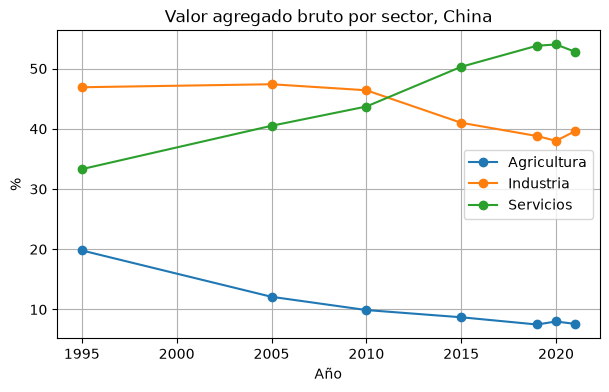

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for sector in china.columns:
    ax.plot(china.index, china[sector], marker="o", label=sector)
ax.set_title("Valor agregado bruto por sector, China")
ax.set_xlabel("Año")
ax.set_ylabel("%")
ax.grid(True, which="both")
ax.legend(loc="center right")
plt.show()

## 5. Leyes de la Gestalt

La psicología de la Gestalt describe cómo el cerebro agrupa lo que ve antes de leerlo. Un buen gráfico usa esas reglas a su favor:

| Ley | Qué dice | Cómo se usa en un gráfico |
| --- | --- | --- |
| **Proximidad** | Lo que está cerca se percibe como un grupo | Etiquetas pegadas a su línea en lugar de una leyenda lejana |
| **Similitud** | Lo que comparte color o forma se percibe como relacionado | Un solo color para el foco y gris para el contexto |
| **Continuidad** | El ojo sigue líneas y trayectorias suaves | Líneas para series temporales; orden lógico en barras |
| **Cierre** | Completamos figuras incompletas | No hacen falta marcos: los ejes x e y bastan para "cerrar" el área |
| **Punto focal** | Lo distinto llama la atención primero | Un color saturado, un tamaño mayor o una anotación sobre lo importante |

El ejemplo siguiente aplica similitud y punto focal: todas las economías del archivo en gris, como contexto, y China en color.

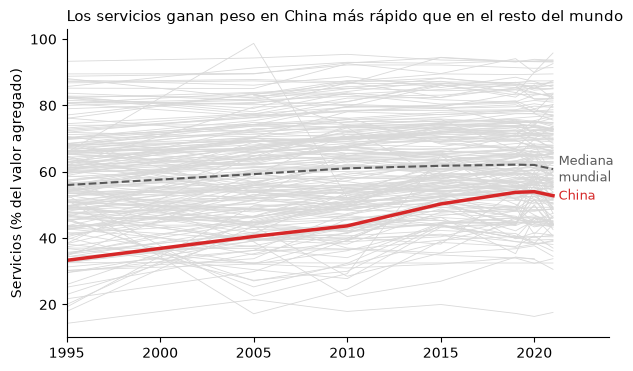

China: 33.3 % → 52.8 %
Mediana: 56.0 % → 60.8 %


In [5]:
servicios = datos[datos["sector"] == "Servicios"].pivot(index="anio", columns="pais", values="valor")
mediana = servicios.median(axis=1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(servicios.index, servicios, color="0.85", lw=0.6)          # contexto
ax.plot(mediana.index, mediana, color="0.35", lw=1.5, ls="--")      # referencia
ax.plot(servicios.index, servicios["China"], color="tab:red", lw=2.5)  # foco

ax.text(2021.3, mediana.iloc[-1], "Mediana\nmundial", va="center", fontsize=9, color="0.35")
ax.text(2021.3, servicios.loc[2021, "China"], "China", va="center", fontsize=9, color="tab:red")
ax.set_title("Los servicios ganan peso en China más rápido que en el resto del mundo",
             loc="left", fontsize=11)
ax.set_ylabel("Servicios (% del valor agregado)")
ax.set_xlim(1995, 2024)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(f"China: {servicios.loc[1995, 'China']} % → {servicios.loc[2021, 'China']} %")
print(f"Mediana: {mediana.loc[1995]:.1f} % → {mediana.loc[2021]:.1f} %")

## 6. Holmes: el adorno memorable

Nigel Holmes, diseñador de infografías para la revista *Time*, defendía lo contrario que Tufte en un punto: los gráficos con ilustraciones, metáforas visuales y cifras grandes **se recuerdan mejor**. Estudios posteriores (Bateman y colaboradores, 2010) encontraron que los gráficos con adornos se interpretaban igual de bien y se recordaban más tiempo después.

Ambas posturas se concilian así: el adorno es aceptable cuando **refuerza el mensaje** y **no distorsiona los datos**. Sus riesgos son:

- **Distorsión:** pictogramas que crecen en área cuando el dato crece en longitud, perspectivas 3D, ejes recortados.
- **Distracción:** la ilustración compite con los datos y el lector recuerda el dibujo, no la cifra.
- **Tono:** lo lúdico puede ser inadecuado en un informe técnico o sobre un tema delicado.

Un recurso "a lo Holmes" que funciona casi siempre es la **cifra protagonista**: el número clave en grande, acompañado de un gráfico mínimo.

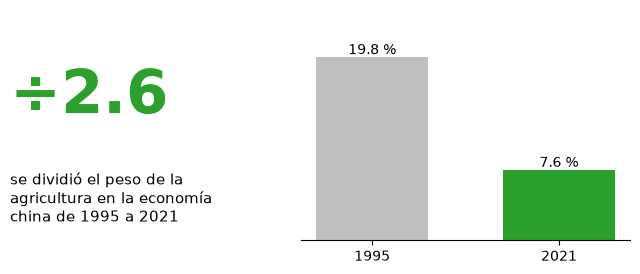

In [6]:
agricultura = china["Agricultura"]

fig, (ax_texto, ax) = plt.subplots(1, 2, figsize=(8, 3), width_ratios=[1, 1.4])
ax_texto.axis("off")
ax_texto.text(0, 0.62, f"÷{agricultura[1995] / agricultura[2021]:.1f}", fontsize=44,
              fontweight="bold", color="tab:green", va="center")
ax_texto.text(0, 0.18, "se dividió el peso de la\nagricultura en la economía\nchina de 1995 a 2021",
              fontsize=11, va="center")

barras = ax.bar(["1995", "2021"], [agricultura[1995], agricultura[2021]],
                color=["0.75", "tab:green"], width=0.6)
ax.bar_label(barras, fmt="%.1f %%", fontsize=10)
ax.set_ylim(0, 25)
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

La cifra grande es el adorno; las barras empiezan en 0 y conservan la proporción real, así que el recurso no engaña.

## 7. Resaltar con color y anotaciones

Dos herramientas concentran casi todo el trabajo narrativo en matplotlib:

- **Color con intención:** gris para el contexto y un único color saturado para lo que importa. Si todo tiene color, nada destaca.
- **`ax.annotate(texto, xy=punto, xytext=posición, arrowprops=...)`:** coloca un texto explicativo y, opcionalmente, una flecha hacia el dato. Con `textcoords="offset points"` la posición del texto se indica en puntos respecto al dato, lo que evita recalcular coordenadas.

Además, las **etiquetas directas** al final de cada línea sustituyen a la leyenda (proximidad), y se eliminan los bordes superior y derecho (`ax.spines[...]`) y la cuadrícula, o se deja solo una cuadrícula horizontal muy tenue.

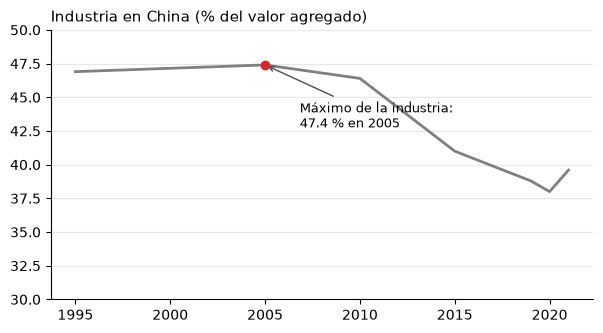

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(china.index, china["Industria"], color="0.5", lw=2)
ax.annotate("Máximo de la industria:\n47.4 % en 2005", xy=(2005, china.loc[2005, "Industria"]),
            xytext=(25, -45), textcoords="offset points", fontsize=9,
            arrowprops={"arrowstyle": "->", "color": "0.3"})
ax.scatter([2005], [china.loc[2005, "Industria"]], color="tab:red", zorder=3)
ax.set_ylim(30, 50)
ax.set_title("Industria en China (% del valor agregado)", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()

## 8. Rediseño: antes y después

Volvamos al gráfico de la sección 4 y apliquemos todo lo anterior:

1. **Título con el mensaje**, en forma de frase, alineado a la izquierda (donde empieza la lectura).
2. **Jerarquía de color:** servicios en color (el protagonista), industria en gris oscuro (el antagonista), agricultura en gris claro.
3. **Etiquetas directas** en lugar de la leyenda.
4. **Anotación** en el momento clave: el cruce entre servicios e industria.
5. **Menos tinta:** sin marco superior y derecho, sin cuadrícula densa, sin marcadores en cada punto.
6. **Eje x con los años reales**, para respetar el salto de 1995 a 2005.

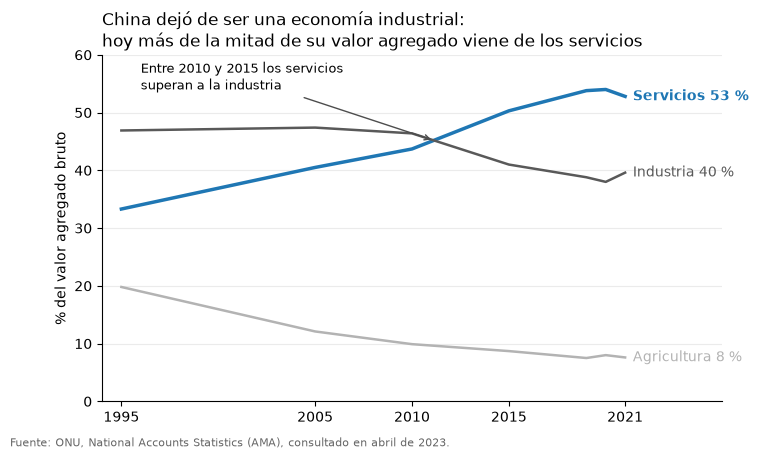

In [8]:
colores = {"Servicios": "tab:blue", "Industria": "0.35", "Agricultura": "0.7"}

fig, ax = plt.subplots(figsize=(8, 4.5))
for sector, color in colores.items():
    ax.plot(china.index, china[sector], color=color, lw=2.5 if sector == "Servicios" else 1.8)
    ax.text(2021.4, china.loc[2021, sector], f"{sector} {china.loc[2021, sector]:.0f} %",
            color=color, va="center", fontsize=10, fontweight="bold" if sector == "Servicios" else None)

# Punto de cruce por interpolación lineal entre 2010 y 2015
d10 = china.loc[2010, "Servicios"] - china.loc[2010, "Industria"]
d15 = china.loc[2015, "Servicios"] - china.loc[2015, "Industria"]
anio_cruce = 2010 + 5 * (-d10) / (d15 - d10)
valor_cruce = np.interp(anio_cruce, china.index, china["Servicios"])
ax.annotate("Entre 2010 y 2015 los servicios\nsuperan a la industria",
            xy=(anio_cruce, valor_cruce), xytext=(1996, 54), fontsize=9.5,
            arrowprops={"arrowstyle": "->", "color": "0.3"})

ax.set_title("China dejó de ser una economía industrial:\nhoy más de la mitad de su valor agregado viene de los servicios",
             loc="left", fontsize=12)
ax.set_ylabel("% del valor agregado bruto")
ax.set_xticks([1995, 2005, 2010, 2015, 2021])    # años reales, sin amontonar 2019-2021
ax.set_xlim(1994, 2026)
ax.set_ylim(0, 60)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
fig.text(0.01, 0.01, "Fuente: ONU, National Accounts Statistics (AMA), consultado en abril de 2023.",
         fontsize=8, color="0.4")
plt.show()

El primer gráfico mostraba los mismos datos, pero dejaba al lector la tarea de encontrar la historia. El segundo la cuenta: el título da la conclusión, el color señala al protagonista, la anotación marca el giro y las etiquetas permiten leer los valores sin buscar la leyenda. La fuente al pie da credibilidad.

## 9. Errores frecuentes

**Tratar años irregulares como categorías equiespaciadas.** Si los años se grafican como texto, o por posición, el salto de diez años entre 1995 y 2005 ocupa el mismo espacio que el de un año entre 2019 y 2020, y la pendiente se exagera. Con los años numéricos en el eje x, la escala es proporcional al tiempo.

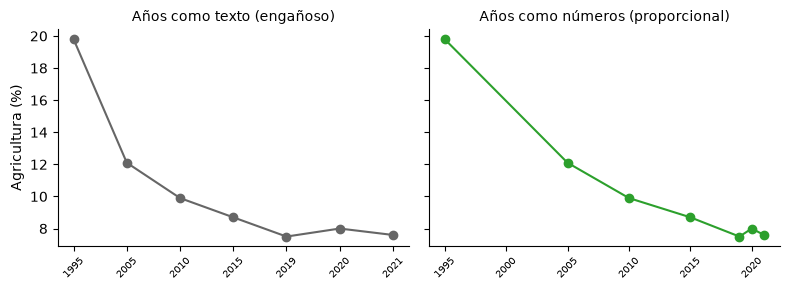

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
axes[0].plot(china.index.astype(str), china["Agricultura"], marker="o", color="0.4")
axes[0].set_title("Años como texto (engañoso)", fontsize=10)
axes[1].plot(china.index, china["Agricultura"], marker="o", color="tab:green")
axes[1].set_title("Años como números (proporcional)", fontsize=10)
axes[0].set_ylabel("Agricultura (%)")
for ax in axes:
    ax.tick_params(axis="x", labelsize=7, rotation=45)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**Renombrar columnas sin mirar su contenido.** Al asignar nombres nuevos a columnas de un archivo con encabezados incompletos es fácil equivocarse: aquí, la columna sin nombre contiene los países, aunque el título del archivo hable de actividades económicas. Conviene imprimir algunos valores de cada columna antes de darle nombre.

**Cortar el eje de un gráfico de barras.** La longitud de una barra representa su valor; si el eje no empieza en 0, una diferencia pequeña parece enorme. En líneas se puede ajustar el rango, en barras no.

**Usar dos ejes y distintos.** Dos escalas verticales en un mismo gráfico permiten "fabricar" cruces y correlaciones moviendo los rangos. Si las magnitudes son distintas, mejor dos gráficos o una escala común (por ejemplo, índice base 100).

**Colorear todo.** Un color distinto por serie, sin jerarquía, impide saber dónde mirar. Más de 5 o 6 colores categóricos ya no se distinguen bien, y los pares rojo-verde son problemáticos para personas con daltonismo.

**Un título que solo describe.** "Valor agregado por sector" dice qué se graficó; "Los servicios superan a la industria" dice qué significa.

## 10. Ejercicio

Queremos contar cómo cambió el peso de la agricultura entre 1995 y 2021 en diez economías: Argentina, Bangladesh, Brazil, Chile, China, Colombia, India, Mexico, Peru y Viet Nam.

1. Construye una tabla con el porcentaje de la agricultura en 1995 y 2021 para esos países y calcula el cambio en puntos porcentuales.
2. Escribe el mensaje principal en una frase con verbo, a partir de los datos.
3. Dibuja un **gráfico de pendiente** (una línea por país entre 1995 y 2021) con todos los países en gris.
4. Resalta en color los países que cuentan la historia (la mayor caída y los que aumentaron), con etiquetas directas en ambos extremos y sin leyenda.
5. Pon como título el mensaje del punto 2 y elimina la tinta innecesaria.

### Solución

In [10]:
seleccion = ["Argentina", "Bangladesh", "Brazil", "Chile", "China",
             "Colombia", "India", "Mexico", "Peru", "Viet Nam"]
agro = (datos[(datos["sector"] == "Agricultura") & datos["pais"].isin(seleccion)]
        .pivot(index="pais", columns="anio", values="valor")[[1995, 2021]])
agro.columns.name = None
agro["cambio"] = agro[2021] - agro[1995]
agro = agro.sort_values("cambio")
print(agro)

mayor_caida = agro["cambio"].idxmin()
suben = agro.index[agro["cambio"] > 0].tolist()
print("\nMayor caída:", mayor_caida, "| aumentan:", suben)

            1995  2021  cambio
pais                          
Bangladesh  26.4  12.1   -14.3
China       19.8   7.6   -12.2
Viet Nam    24.5  13.6   -10.9
India       27.4  18.6    -8.8
Chile        5.9   3.7    -2.2
Peru         8.9   7.6    -1.3
Colombia     9.2   8.2    -1.0
Mexico       4.6   4.1    -0.5
Argentina    5.3   7.2     1.9
Brazil       5.5   8.1     2.6

Mayor caída: Bangladesh | aumentan: ['Argentina', 'Brazil']


**Mensaje:** "La agricultura pierde peso en Asia: en Bangladesh cae a menos de la mitad, mientras en Argentina y Brasil gana terreno". Es una frase con verbo, cita los extremos y anticipa el contraste que mostrará el gráfico.

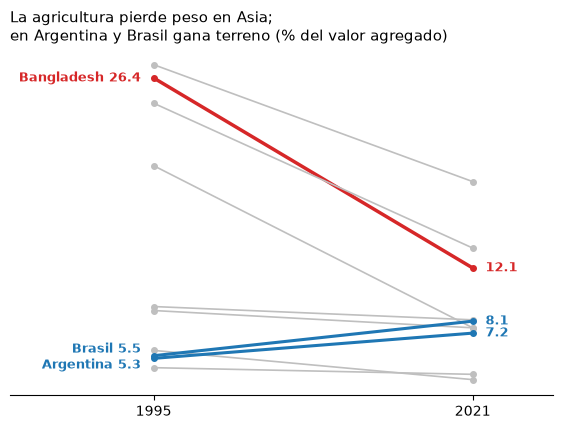

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for pais, fila in agro.iterrows():
    if pais == mayor_caida:
        color, lw, peso = "tab:red", 2.5, "bold"
    elif pais in suben:
        color, lw, peso = "tab:blue", 2.2, "bold"
    else:
        color, lw, peso = "0.75", 1.2, None
    ax.plot([0, 1], [fila[1995], fila[2021]], color=color, lw=lw, marker="o", ms=4)
    if color != "0.75":
        # Desplazamiento vertical para que no se encimen etiquetas con valores casi iguales
        ajuste = {"Brazil": 0.5, "Argentina": -0.5}.get(pais, 0)
        nombre = {"Brazil": "Brasil"}.get(pais, pais)
        ax.text(-0.04, fila[1995] + ajuste, f"{nombre} {fila[1995]:.1f}", ha="right", va="center",
                color=color, fontsize=9, fontweight=peso)
        ax.text(1.04, fila[2021], f"{fila[2021]:.1f}", ha="left", va="center",
                color=color, fontsize=9, fontweight=peso)

ax.set_xticks([0, 1], ["1995", "2021"])
ax.set_xlim(-0.45, 1.25)
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_title("La agricultura pierde peso en Asia;\nen Argentina y Brasil gana terreno (% del valor agregado)",
             loc="left", fontsize=11)
plt.show()

Las líneas grises dan el contexto (casi todas bajan), el rojo marca la caída más fuerte y el azul, la excepción. Las etiquetas en los extremos hacen innecesarios el eje y la leyenda.

## Resumen

- Una historia con datos tiene **mensaje**, **audiencia** y **arco narrativo**; el mensaje debe caber en una frase con verbo.
- El gráfico se elige por la pregunta: líneas para evolución, barras desde 0 para comparar, pendiente para dos momentos.
- **Tufte:** maximizar la proporción datos-tinta y eliminar el *chartjunk*. **Holmes:** el adorno es válido si refuerza el mensaje sin distorsionar.
- La **Gestalt** (proximidad, similitud, continuidad, cierre, punto focal) explica por qué funcionan las etiquetas directas y el gris con un solo color de foco.
- En matplotlib, `ax.annotate`, `ax.text`, `ax.spines` y un título con la conclusión transforman un gráfico correcto en uno que comunica.

Este módulo cierra el programa. Los proyectos de la carpeta [`proyectos/`](../../proyectos/) integran lo aprendido de principio a fin: análisis de reseñas de aplicaciones (P01), aprendizaje supervisado (P02), segmentación de clientes (P03), análisis de películas con SQL (P04) y un tablero sobre COVID-19 en Power BI (P05).